# Part B — Notebook 03a: I-JEPA SSL Pretraining + Diagnostics

**CSE 445 — Computer Vision | East West University**

I-JEPA pretrains a Vision Transformer via masked **latent** prediction (no pixel reconstruction, no hand-crafted augmentations): a context encoder sees visible patches, an EMA target encoder produces representations for masked target blocks, and a predictor learns to predict those target representations from the context. 

**Integration route used in this notebook: distillation.** After the ViT is trained via the I-JEPA objective, its frozen representations are distilled into a YOLOv12s-matched CNN backbone via a feature-matching loss, so the exported checkpoint loads into the detector exactly like SimCLR/BYOL's (see Section 3's Backbone Integration Strategy note). If your group prefers the ViT-adapter route instead, replace Section 8 below with your FPN adapter and skip the CNN distillation stage.

Notebook order: Config → Dataset locate → Re-derive the 10/10/80 partition (SSL pool only) → View/mask pipeline demo → Model definition → Training loop (30 epochs) → Representation diagnostics (t-SNE/UMAP + nearest-neighbour retrieval) → Checkpoint export.

**Output of this notebook:** `ijepa_backbone.pt`, to be published as a Kaggle dataset (e.g. `group-i-partb-ssl-checkpoints`) and attached as an input to Notebook 03b.

## 0. Setup

In [1]:
!pip install -q ultralytics==8.3.* pyyaml scikit-learn umap-learn timm

import os, sys, json, yaml, random, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
from ultralytics import YOLO

print('Torch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.10.0+cu128 | CUDA available: True


## 1. Config Cell

In [2]:
CONFIG = {
    'method_name': 'ijepa',
    'encoder_desc': 'ViT-Small encoder (context/target) + CNN distillation target',
    'architecture_base': 'yolo12s',
    'backbone_cutoff': 9,   # layers 0..cutoff of yolo12s.yaml = backbone (verify against printout)

    'seed': 42,
    'test_frac': 0.10,
    'val_frac': 0.10,

    "dataset_path": Path("/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version"),
    "work_dir": Path("/kaggle/working"),

    'imgsz': 224,          # SSL pretraining resolution (smaller than detection 640 to fit a T4 session)
    'batch': 64,
    'epochs': 30,
    'lr': 3e-4,
    'weight_decay': 1e-6,
    'num_workers': 2,
    'amp': True,           # mixed precision — documented per assignment's T4-budget allowance
    'patch_size': 16,
    'vit_embed_dim': 384,
    'vit_depth': 6,
    'vit_heads': 6,
    'ema_momentum': 0.996,
    'num_target_blocks': 4,
    'target_block_scale': (0.15, 0.2),   # fraction of patches per target block
    'context_scale': (0.85, 1.0),        # fraction of patches kept as context (rest masked)
    'var_loss_weight': 1.0,   # VICReg-style anti-collapse regularizer weight (see Section 6)
    'distill_epochs': 10,                # Stage 2: distil frozen ViT into the CNN backbone
    'distill_lr': 3e-4,
}

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
CONFIG

{'method_name': 'ijepa',
 'encoder_desc': 'ViT-Small encoder (context/target) + CNN distillation target',
 'architecture_base': 'yolo12s',
 'backbone_cutoff': 9,
 'seed': 42,
 'test_frac': 0.1,
 'val_frac': 0.1,
 'dataset_path': PosixPath('/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version'),
 'work_dir': PosixPath('/kaggle/working'),
 'imgsz': 224,
 'batch': 64,
 'epochs': 30,
 'lr': 0.0003,
 'weight_decay': 1e-06,
 'num_workers': 2,
 'amp': True,
 'patch_size': 16,
 'vit_embed_dim': 384,
 'vit_depth': 6,
 'vit_heads': 6,
 'ema_momentum': 0.996,
 'num_target_blocks': 4,
 'target_block_scale': (0.15, 0.2),
 'context_scale': (0.85, 1.0),
 'var_loss_weight': 1.0,
 'distill_epochs': 10,
 'distill_lr': 0.0003}

## 2. Locate the Part A Dataset (FLIR)

In [3]:
DATASET_PATH = CONFIG['dataset_path']

def find_first_existing(base: Path, candidates):
    for c in candidates:
        p = base / c
        if p.exists():
            return p
    for c in candidates:
        matches = list(base.rglob(Path(c).name))
        if matches:
            return matches[0]
    return None

def locate_dataset_root(base: Path) -> Path:
    if (base / 'data.yaml').exists():
        return base
    matches = list(base.rglob('data.yaml'))
    if matches:
        return matches[0].parent
    raise FileNotFoundError(f'Could not locate data.yaml under {base}')

DATASET_ROOT = locate_dataset_root(DATASET_PATH)
DATA_YAML = DATASET_ROOT / 'data.yaml'

def locate_split_dir(root: Path, split: str, kind: str):
    candidates = [f'{split}/{kind}', f'{split}s/{kind}', f'{kind}/{split}', f'{split}']
    for c in candidates:
        p = root / c
        if p.exists() and any(p.iterdir()):
            return p
    for p in root.rglob('*'):
        if p.is_dir() and split in p.parts and kind in p.name.lower():
            return p
    return None

TRAIN_IMAGES = locate_split_dir(DATASET_ROOT, 'train', 'images')
TRAIN_LABELS = locate_split_dir(DATASET_ROOT, 'train', 'labels')
VALID_IMAGES = locate_split_dir(DATASET_ROOT, 'valid', 'images')
VALID_LABELS = locate_split_dir(DATASET_ROOT, 'valid', 'labels')
TEST_IMAGES  = locate_split_dir(DATASET_ROOT, 'test', 'images')
TEST_LABELS  = locate_split_dir(DATASET_ROOT, 'test', 'labels')

with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

NUM_CLASSES = data_cfg.get('nc', 3)
CLASS_NAMES = data_cfg.get('names', ['car', 'dog', 'person'])
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES)]
print('Dataset root:', DATASET_ROOT, '| Classes:', NUM_CLASSES, CLASS_NAMES)

Dataset root: /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version | Classes: 3 ['car', 'dog', 'person']


## 3. Re-Derive the Leakage-Safe Partition (SSL pool only)

In [4]:
# Re-derive the SAME 10/10/80 leakage-safe partition used in Notebook *b (same seed,
# same pooling order -> identical split). Only the SSL pool (80%) is used for pretraining;
# labels are never read here.
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def collect_pairs(img_dir, lbl_dir):
    if img_dir is None:
        return []
    pairs = []
    for img_path in sorted(img_dir.iterdir()):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        lbl_path = (lbl_dir / (img_path.stem + '.txt')) if lbl_dir else None
        pairs.append((img_path, lbl_path if (lbl_path and lbl_path.exists()) else None))
    return pairs

all_pairs = (collect_pairs(TRAIN_IMAGES, TRAIN_LABELS)
             + collect_pairs(VALID_IMAGES, VALID_LABELS)
             + collect_pairs(TEST_IMAGES, TEST_LABELS))

seen, dedup = set(), []
for img_path, lbl_path in all_pairs:
    if img_path.stem in seen:
        continue
    seen.add(img_path.stem)
    dedup.append((img_path, lbl_path))

dedup.sort(key=lambda t: t[0].name)
rng = random.Random(CONFIG['seed'])
rng.shuffle(dedup)

n_total = len(dedup)
n_test  = int(round(n_total * CONFIG['test_frac']))
n_val   = int(round(n_total * CONFIG['val_frac']))

test_pairs = dedup[:n_test]
val_pairs  = dedup[n_test:n_test + n_val]
ssl_pool   = dedup[n_test + n_val:]

test_stems = {p.stem for p, _ in test_pairs}
val_stems  = {p.stem for p, _ in val_pairs}
pool_stems = {p.stem for p, _ in ssl_pool}
assert not (test_stems & pool_stems) and not (val_stems & pool_stems), 'LEAKAGE detected!'

ssl_pool_images = [img for img, _ in ssl_pool]           # labels intentionally discarded
val_images_with_labels = [(img, lbl) for img, lbl in val_pairs if lbl is not None]

print(f'Total: {n_total} | Test: {len(test_pairs)} | Val: {len(val_pairs)} | SSL pool: {len(ssl_pool_images)}')
print('Verified: test and val are disjoint from the SSL pool.')

Total: 26061 | Test: 2606 | Val: 2606 | SSL pool: 20849
Verified: test and val are disjoint from the SSL pool.


## 4. I-JEPA Data Pipeline — No Hand-Crafted Augmentations

I-JEPA deliberately avoids augmentation-based invariance (no crop/color-jitter view pairs). The only transform is resize + normalize; the learning signal comes entirely from masking.

In [5]:
ijepa_transform = T.Compose([
    T.Resize((CONFIG['imgsz'], CONFIG['imgsz'])),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class IJEPADataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths, self.transform = image_paths, transform
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        return self.transform(img)

train_dataset = IJEPADataset(ssl_pool_images, ijepa_transform)
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch'], shuffle=True,
                           num_workers=CONFIG['num_workers'], drop_last=True, pin_memory=True)
n_patches_side = CONFIG['imgsz'] // CONFIG['patch_size']
N_PATCHES = n_patches_side ** 2
print(f'{n_patches_side}x{n_patches_side} = {N_PATCHES} patches/image | {len(train_loader)} batches/epoch')

14x14 = 196 patches/image | 325 batches/epoch


### Demo: context / target block mask for one image

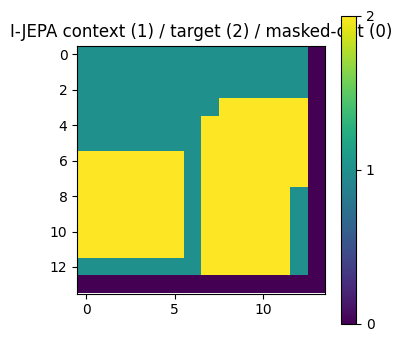

In [6]:
def sample_ijepa_masks(n_patches_side, num_target_blocks, target_scale, context_scale, rng):
    n = n_patches_side
    total = n * n
    target_masks = []
    covered = set()
    for _ in range(num_target_blocks):
        scale = rng.uniform(*target_scale)
        block_area = max(1, int(scale * total))
        bh = bw = max(1, int(math.sqrt(block_area)))
        top = rng.randint(0, max(0, n - bh)); left = rng.randint(0, max(0, n - bw))
        idxs = [ (r*n + c) for r in range(top, min(n, top+bh)) for c in range(left, min(n, left+bw)) ]
        target_masks.append(set(idxs))
        covered |= set(idxs)
    ctx_scale = rng.uniform(*context_scale)
    ctx_area = max(1, int(ctx_scale * total))
    bh = bw = max(1, int(math.sqrt(ctx_area)))
    top = rng.randint(0, max(0, n - bh)); left = rng.randint(0, max(0, n - bw))
    context_idxs = set((r*n + c) for r in range(top, min(n, top+bh)) for c in range(left, min(n, left+bw)))
    context_idxs -= covered   # target blocks are always masked OUT of the context, per spec
    return sorted(context_idxs), [sorted(t) for t in target_masks]

demo_rng = random.Random(0)
ctx_idx, tgt_idxs = sample_ijepa_masks(n_patches_side, CONFIG['num_target_blocks'],
                                        CONFIG['target_block_scale'], CONFIG['context_scale'], demo_rng)
grid = np.zeros((n_patches_side, n_patches_side))
for idx in ctx_idx: grid[idx // n_patches_side, idx % n_patches_side] = 1        # context = 1
for t in tgt_idxs:
    for idx in t: grid[idx // n_patches_side, idx % n_patches_side] = 2          # target = 2
plt.figure(figsize=(4,4))
plt.imshow(grid, cmap='viridis'); plt.title('I-JEPA context (1) / target (2) / masked-out (0)')
plt.colorbar(ticks=[0,1,2]); plt.show()

## 5. Model Definition — ViT Context/Target Encoders + Predictor

A compact ViT-Small (patch16) built directly in PyTorch — no external pretrained weights, per the assignment's requirement that I-JEPA be run from scratch on the unlabelled pool.

In [7]:
class PatchEmbed(nn.Module):
    def __init__(self, img_size, patch_size, in_ch=3, embed_dim=384):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.n_patches = (img_size // patch_size) ** 2
    def forward(self, x):
        x = self.proj(x)                      # (B, D, H', W')
        return x.flatten(2).transpose(1, 2)    # (B, N, D)

class SimpleViT(nn.Module):
    def __init__(self, img_size, patch_size, embed_dim, depth, heads):
        super().__init__()
        self.patch_embed = PatchEmbed(img_size, patch_size, 3, embed_dim)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.patch_embed.n_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=heads,
                                            dim_feedforward=embed_dim*4, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth)
        self.embed_dim = embed_dim
    def forward(self, x, patch_indices=None):
        tokens = self.patch_embed(x) + self.pos_embed
        if patch_indices is not None:
            tokens = tokens[:, patch_indices, :]
        return self.encoder(tokens)            # (B, len(patch_indices) or N, D)

class Predictor(nn.Module):
    def __init__(self, embed_dim, depth=2, heads=6):
        super().__init__()
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=heads,
                                            dim_feedforward=embed_dim*4, batch_first=True)
        self.net = nn.TransformerEncoder(layer, num_layers=depth)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        nn.init.trunc_normal_(self.mask_token, std=0.02)
    def forward(self, context_repr, n_target_tokens):
        mask_tokens = self.mask_token.expand(context_repr.shape[0], n_target_tokens, -1)
        x = torch.cat([context_repr, mask_tokens], dim=1)
        out = self.net(x)
        return out[:, -n_target_tokens:, :]

context_encoder = SimpleViT(CONFIG['imgsz'], CONFIG['patch_size'], CONFIG['vit_embed_dim'],
                             CONFIG['vit_depth'], CONFIG['vit_heads']).to(DEVICE)
predictor_ijepa = Predictor(CONFIG['vit_embed_dim'], depth=2, heads=CONFIG['vit_heads']).to(DEVICE)

import copy
target_encoder_vit = copy.deepcopy(context_encoder).to(DEVICE)
for p in target_encoder_vit.parameters(): p.requires_grad = False

@torch.no_grad()
def ema_update(online_model, target_model, momentum):
    for po, pt in zip(online_model.parameters(), target_model.parameters()):
        pt.data = momentum * pt.data + (1 - momentum) * po.data

print('I-JEPA context encoder, EMA target encoder, and predictor initialised.')

I-JEPA context encoder, EMA target encoder, and predictor initialised.


## 6. Training Loop — Masked Latent Prediction (30 epochs)

**Anti-collapse regularizer.** JEPA-style Siamese predictors (like BYOL) can converge to a trivial fixed point where the encoder outputs the same representation for every image — the prediction loss then looks great, but the features carry no information. This is checked for directly in Section 7's diagnostics (near-zero nearest-neighbour distances between visually unrelated images is the tell). A VICReg-style variance term is added to the loss below: it penalises any embedding dimension whose standard deviation across the batch drops below 1, which makes the collapsed fixed point non-optimal.

In [8]:
def variance_loss(z, gamma=1.0, eps=1e-4):
    """VICReg-style anti-collapse term: penalises low per-dimension std across the batch."""
    std = torch.sqrt(z.var(dim=0) + eps)
    return F.relu(gamma - std).mean()

params = list(context_encoder.parameters()) + list(predictor_ijepa.parameters())
optimizer = torch.optim.AdamW(params, lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scaler = torch.cuda.amp.GradScaler(enabled=CONFIG['amp'])
mask_rng = random.Random(CONFIG['seed'])

loss_history, pred_loss_history, var_loss_history = [], [], []
for epoch in range(CONFIG['epochs']):
    context_encoder.train(); predictor_ijepa.train()
    running_loss = running_pred = running_var = 0.0
    for imgs in train_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        ctx_idx, tgt_idxs = sample_ijepa_masks(n_patches_side, CONFIG['num_target_blocks'],
                                                CONFIG['target_block_scale'], CONFIG['context_scale'], mask_rng)
        if len(ctx_idx) == 0 or any(len(t) == 0 for t in tgt_idxs):
            continue
        all_tgt_idx = sorted(set().union(*tgt_idxs))
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=CONFIG['amp']):
            ctx_repr = context_encoder(imgs, patch_indices=ctx_idx)
            with torch.no_grad():
                tgt_repr = target_encoder_vit(imgs, patch_indices=all_tgt_idx)
            pred_repr = predictor_ijepa(ctx_repr, len(all_tgt_idx))
            pred_loss = F.smooth_l1_loss(pred_repr, tgt_repr)
            # anti-collapse term: computed on the context encoder's own pooled output (not
            # the predictor's), since it is the context encoder that gets exported/distilled —
            # penalising it directly is what stops it from collapsing to a constant vector.
            var_term = variance_loss(ctx_repr.mean(dim=1))
            loss = pred_loss + CONFIG['var_loss_weight'] * var_term
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        ema_update(context_encoder, target_encoder_vit, CONFIG['ema_momentum'])
        running_loss += loss.item(); running_pred += pred_loss.item(); running_var += var_term.item()
    n_b = max(1, len(train_loader))
    epoch_loss, epoch_pred, epoch_var = running_loss/n_b, running_pred/n_b, running_var/n_b
    loss_history.append(epoch_loss); pred_loss_history.append(epoch_pred); var_loss_history.append(epoch_var)
    print(f'Epoch {epoch+1}/{CONFIG["epochs"]} | total: {epoch_loss:.4f} | pred: {epoch_pred:.4f} | var-penalty: {epoch_var:.4f}')

/tmp/ipykernel_23/3013801339.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=CONFIG['amp'])
/tmp/ipykernel_23/3013801339.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=CONFIG['amp']):


Epoch 1/30 | total: 0.4843 | pred: 0.3913 | var-penalty: 0.0931
Epoch 2/30 | total: 1.1635 | pred: 0.2169 | var-penalty: 0.9466
Epoch 3/30 | total: 1.0163 | pred: 0.0760 | var-penalty: 0.9403
Epoch 4/30 | total: 0.4672 | pred: 0.1445 | var-penalty: 0.3227
Epoch 5/30 | total: 0.6110 | pred: 0.6087 | var-penalty: 0.0023
Epoch 6/30 | total: 0.6352 | pred: 0.6332 | var-penalty: 0.0020
Epoch 7/30 | total: 0.6373 | pred: 0.6363 | var-penalty: 0.0010
Epoch 8/30 | total: 0.6423 | pred: 0.6409 | var-penalty: 0.0013
Epoch 9/30 | total: 0.6475 | pred: 0.6468 | var-penalty: 0.0007
Epoch 10/30 | total: 0.6485 | pred: 0.6478 | var-penalty: 0.0007
Epoch 11/30 | total: 0.6625 | pred: 0.6618 | var-penalty: 0.0007
Epoch 12/30 | total: 0.6685 | pred: 0.6680 | var-penalty: 0.0005
Epoch 13/30 | total: 0.6726 | pred: 0.6719 | var-penalty: 0.0006
Epoch 14/30 | total: 0.6706 | pred: 0.6700 | var-penalty: 0.0006
Epoch 15/30 | total: 0.6848 | pred: 0.6846 | var-penalty: 0.0002
Epoch 16/30 | total: 0.6929 | pred

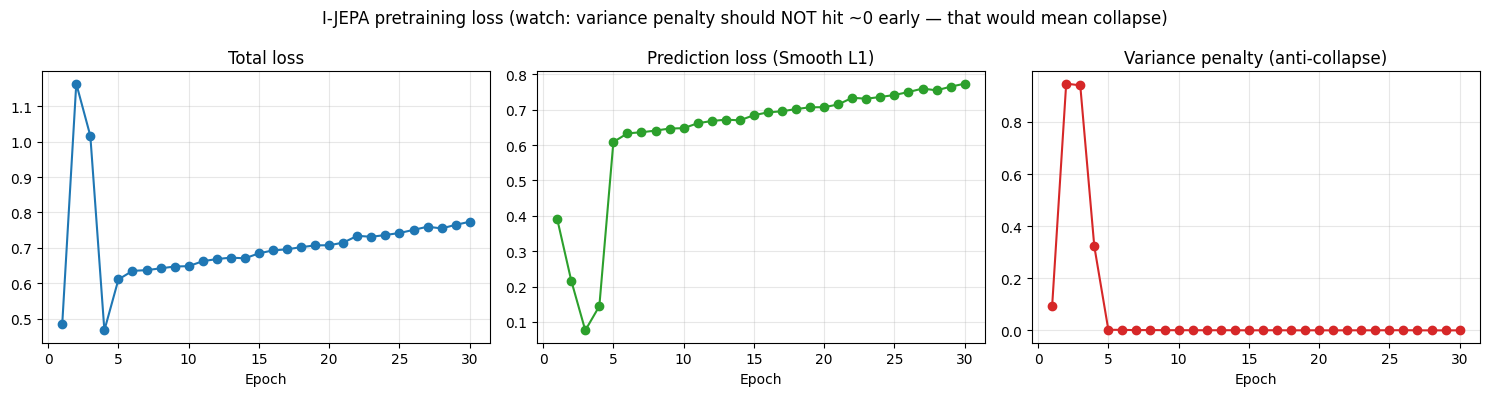

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, hist, label, color in zip(
    axes, [loss_history, pred_loss_history, var_loss_history],
    ['Total loss', 'Prediction loss (Smooth L1)', 'Variance penalty (anti-collapse)'],
    ['tab:blue', 'tab:green', 'tab:red']):
    ax.plot(range(1, len(hist)+1), hist, marker='o', color=color)
    ax.set_xlabel('Epoch'); ax.set_title(label); ax.grid(alpha=0.3)
plt.suptitle('I-JEPA pretraining loss (watch: variance penalty should NOT hit ~0 early — that would mean collapse)')
plt.tight_layout()
plt.savefig(CONFIG['work_dir'] / 'ijepa_loss_curve.png', dpi=150)
plt.show()

## 7. Representation Diagnostics (on the trained ViT context encoder)

Embeddings shape: (200, 384)


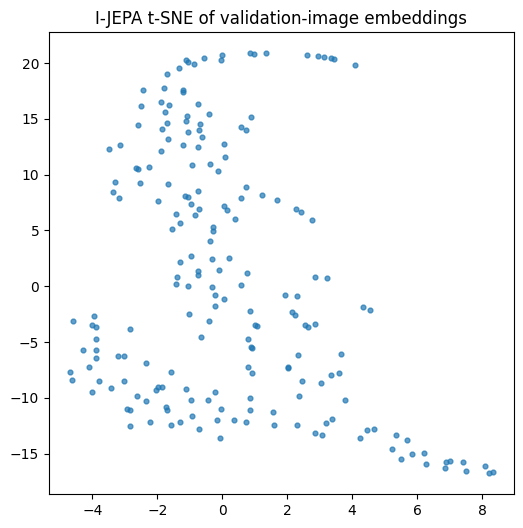

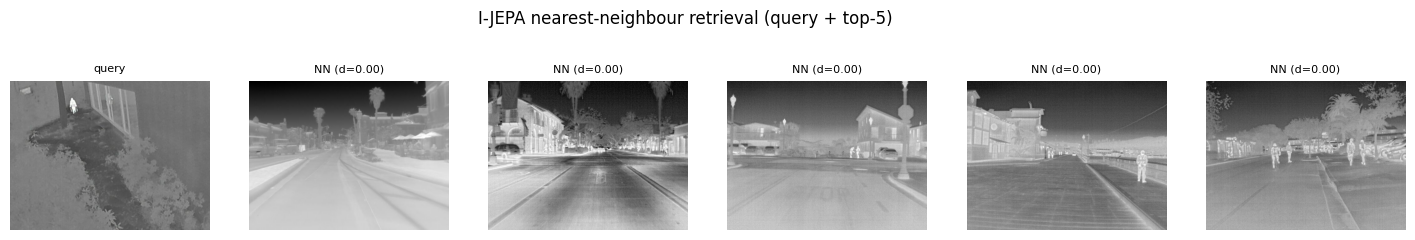

In [10]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

diag_transform = T.Compose([
    T.Resize((CONFIG['imgsz'], CONFIG['imgsz'])), T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

sample_val = val_images_with_labels[:200] if len(val_images_with_labels) > 200 else val_images_with_labels
context_encoder.eval()
embeddings, img_paths_used = [], []
with torch.no_grad():
    for img_path, _ in sample_val:
        x = diag_transform(Image.open(img_path).convert('RGB')).unsqueeze(0).to(DEVICE)
        repr_full = context_encoder(x, patch_indices=None)   # all patches (full context)
        emb = repr_full.mean(dim=1).squeeze(0).cpu().numpy()  # mean-pool patch tokens
        embeddings.append(emb); img_paths_used.append(img_path)
embeddings = np.stack(embeddings)
print('Embeddings shape:', embeddings.shape)

tsne = TSNE(n_components=2, random_state=CONFIG['seed'], perplexity=min(30, len(embeddings)-1))
emb_2d = tsne.fit_transform(embeddings)
plt.figure(figsize=(6,6))
plt.scatter(emb_2d[:,0], emb_2d[:,1], s=12, alpha=0.7)
plt.title('I-JEPA t-SNE of validation-image embeddings')
plt.savefig(CONFIG['work_dir'] / 'ijepa_tsne.png', dpi=150)
plt.show()

nn_model = NearestNeighbors(n_neighbors=6).fit(embeddings)
query_idx = 0
dists, idxs = nn_model.kneighbors(embeddings[query_idx:query_idx+1])
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, i in zip(axes, idxs[0]):
    ax.imshow(Image.open(img_paths_used[i]).convert('RGB')); ax.axis('off')
    ax.set_title('query' if i == query_idx else f'NN (d={dists[0][list(idxs[0]).index(i)]:.2f})', fontsize=8)
plt.suptitle('I-JEPA nearest-neighbour retrieval (query + top-5)')
plt.savefig(CONFIG['work_dir'] / 'ijepa_retrieval.png', dpi=150)
plt.show()

# Comment (fill in after inspecting the plots above):
# Does the t-SNE layout organise images by visually/semantically similar target-class content?

## 8. Distillation — Transfer the Trained ViT into a YOLOv12s-Matched CNN Backbone

Stage 2 of the distillation integration route: the frozen, I-JEPA-trained ViT context encoder is used as a teacher; a CNN backbone matched to YOLOv12s (layers 0-9) is trained to match its pooled representation via a lightweight feature-matching loss. This produces a checkpoint that loads into the detector exactly like SimCLR/BYOL's.

In [11]:
class YOLOv12sBackboneEncoder(nn.Module):
    """
    Wraps the first `cutoff+1` layers of a yolo12s.yaml graph as a standalone encoder,
    re-implementing ultralytics' internal forward-graph walk (handles the skip/concat
    connections used by layers whose `.f` attribute is not -1), truncated at `cutoff`.
    Exists so this notebook's pretrained weights can be loaded key-for-key into the
    YOLOv12s backbone in Notebook *b's weight-surgery cell.
    """
    def __init__(self, num_classes=3, cutoff=9):
        super().__init__()
        base = YOLO('yolo12s.yaml').model
        base.nc = num_classes
        self.layers = base.model            # nn.Sequential, full graph (backbone+neck+head)
        self.save = set(base.save)           # indices whose outputs feed later layers
        self.cutoff = cutoff
        # probe output channel count at the cutoff layer with a dummy forward pass
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feat = self._forward_backbone(dummy)
        self.out_channels = feat.shape[1]

    def _forward_backbone(self, x):
        y = []
        out = None
        for i, m in enumerate(self.layers):
            if i > self.cutoff:
                break
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x if i in self.save else None)
            out = x
        return out

    def forward(self, x):
        return self._forward_backbone(x)      # returns the final backbone feature map (B, C, H, W)

    def pooled(self, x):
        feat = self.forward(x)
        return F.adaptive_avg_pool2d(feat, 1).flatten(1)   # (B, C)

    def backbone_state_dict(self):
        """State dict with keys prefixed to match YOLO('yolo12s.yaml').model.state_dict() keys
        exactly (e.g. 'model.0.conv.weight'), so Notebook *b's literal-key match succeeds."""
        sd = {}
        for k, v in self.layers.state_dict().items():
            layer_idx = int(k.split('.', 1)[0])
            if layer_idx <= self.cutoff:
                sd[f'model.{k}'] = v
        return sd

print('YOLOv12sBackboneEncoder defined.')

YOLOv12sBackboneEncoder defined.


Distill epoch 1/10 | feature-matching loss: 0.0001
Distill epoch 2/10 | feature-matching loss: 0.0000
Distill epoch 3/10 | feature-matching loss: 0.0000
Distill epoch 4/10 | feature-matching loss: 0.0000
Distill epoch 5/10 | feature-matching loss: 0.0000
Distill epoch 6/10 | feature-matching loss: 0.0000
Distill epoch 7/10 | feature-matching loss: 0.0000
Distill epoch 8/10 | feature-matching loss: 0.0000
Distill epoch 9/10 | feature-matching loss: 0.0000
Distill epoch 10/10 | feature-matching loss: 0.0000


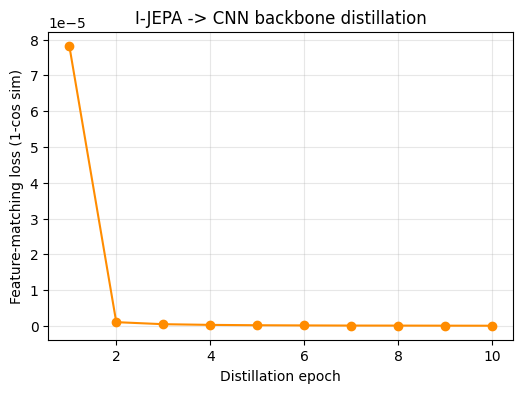

In [12]:
cnn_encoder = YOLOv12sBackboneEncoder(num_classes=NUM_CLASSES, cutoff=CONFIG['backbone_cutoff']).to(DEVICE)
distill_proj = nn.Linear(cnn_encoder.out_channels, CONFIG['vit_embed_dim']).to(DEVICE)
context_encoder.eval()
for p in context_encoder.parameters(): p.requires_grad = False

distill_loader = DataLoader(IJEPADataset(ssl_pool_images, ijepa_transform),
                             batch_size=CONFIG['batch'], shuffle=True,
                             num_workers=CONFIG['num_workers'], drop_last=True, pin_memory=True)

distill_opt = torch.optim.AdamW(list(cnn_encoder.parameters()) + list(distill_proj.parameters()),
                                 lr=CONFIG['distill_lr'])
distill_loss_history = []
for epoch in range(CONFIG['distill_epochs']):
    cnn_encoder.train(); distill_proj.train()
    running = 0.0
    for imgs in distill_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        with torch.no_grad():
            teacher_feat = context_encoder(imgs, patch_indices=None).mean(dim=1)   # (B, vit_dim)
        student_feat = distill_proj(cnn_encoder.pooled(imgs))                       # (B, vit_dim)
        loss = F.mse_loss(F.normalize(student_feat, dim=1), F.normalize(teacher_feat, dim=1))
        distill_opt.zero_grad(); loss.backward(); distill_opt.step()
        running += loss.item()
    epoch_loss = running / len(distill_loader)
    distill_loss_history.append(epoch_loss)
    print(f'Distill epoch {epoch+1}/{CONFIG["distill_epochs"]} | feature-matching loss: {epoch_loss:.4f}')

plt.figure(figsize=(6,4))
plt.plot(range(1, len(distill_loss_history)+1), distill_loss_history, marker='o', color='darkorange')
plt.xlabel('Distillation epoch'); plt.ylabel('Feature-matching loss (1-cos sim)')
plt.title('I-JEPA -> CNN backbone distillation'); plt.grid(alpha=0.3)
plt.savefig(CONFIG['work_dir'] / 'ijepa_distill_loss_curve.png', dpi=150)
plt.show()

## 9. Checkpoint Export

In [13]:
ckpt_path = CONFIG['work_dir'] / 'ijepa_backbone.pt'
torch.save({'state_dict': cnn_encoder.backbone_state_dict(), 'method': 'ijepa',
            'integration_route': 'distillation', 'config': CONFIG}, ckpt_path)
print('Saved', ckpt_path)
print('Publish /kaggle/working as a Kaggle dataset (e.g. group-i-partb-ssl-checkpoints) so Notebook 03b can attach it as an input.')

Saved /kaggle/working/ijepa_backbone.pt
Publish /kaggle/working as a Kaggle dataset (e.g. group-i-partb-ssl-checkpoints) so Notebook 03b can attach it as an input.


## 10. Viva Prep — Notes to Fill In (I-JEPA)

- What predicting in representation (not pixel) space buys you over a masked autoencoder:
- How context/target blocks are sampled and why target blocks are excluded from context:
- Why no hand-crafted augmentations, and what replaces the invariance signal:
- Which integration route you used (adapter vs. distillation) and the trade-off:
- How ViT patch tokens were mapped toward multi-scale P3/P4/P5 features:
- Diagnostic evidence that spatially localised, detection-useful features were learned: